# Parentheticals: how much of the corpus is real?

**Exploratory, not a pipeline.** This notebook tests the parentheticals corpus
(`data/raw/parantheticals/`) before more is built on it. It covers three open
questions from Task 3:

1. Is the cycle-41 repetition an extraction artifact? (§1–§4)
2. Can MP surnames be lemmatised correctly without an external gazetteer? (§6)
3. Can `Mi Hazánk` be kept as one name? (§7)

Nothing here changes `src/` or the published Task 3/4 outputs. Every number that
would move is shown next to the number it would replace. Every repair is a
prototype, listed in §8 under what to promote.

Findings, in one place: see **§8**.

In [1]:
import hashlib
import json
import re
import subprocess
from collections import Counter, defaultdict
from functools import lru_cache
from itertools import groupby
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from parlamonitor.loading import DATA_RAW, load_speeches
from parlamonitor.parentheticals import (
    CYCLES,
    NORMALISATION_VERSION,
    collapse_consecutive,
    file_sha256,
    load_parentheticals,
    parentheticals_path,
)
from parlamonitor.reactions import Kind, events_in

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DERIVED = ROOT / "data" / "derived"
SCRATCH = DERIVED / "explore"
SCRATCH.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)


def rel(path):
    # Repo-relative path for anything printed: these outputs are committed.
    path = Path(path).resolve()
    try:
        return str(path.relative_to(ROOT))
    except ValueError:
        return path.name

## Parameters and provenance

Each parameter here changes the numbers below. Each one is a decision for a
human, not a default this notebook settled.

In [2]:
PARAMS = {
    # Block-duplication detector (§2): the file is run-length encoded, so a run of
    # identical lines is one unit; a window of this many consecutive runs that has
    # already occurred earlier in the same file marks every line in it as a copy.
    "block_window_runs": 10,
    # Name repair (§6): only full name sequences seen in the corpus are matched.
    "name_sources": ["interjector and addressee names (reactions.events_in)", "cycle-43 speaker labels"],
}

commit = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True
).stdout.strip()
corpus = {cycle: load_parentheticals(cycle)[0] for cycle in CYCLES}
provenance = {
    "git_commit": commit,
    "normalisation": NORMALISATION_VERSION,
    "sources": [
        {"cycle": c, "path": rel(parentheticals_path(c)), "sha256": file_sha256(parentheticals_path(c))[:16], "lines": len(corpus[c])}
        for c in CYCLES
    ],
    "speeches": rel(DATA_RAW / "cycle43-speeches.jsonl"),
    "lemma_cache": rel(DERIVED / "parentheticals" / "lemma_cache.jsonl"),
    "params": PARAMS,
}
print(json.dumps(provenance, indent=1, ensure_ascii=False))

{
 "git_commit": "8d62702",
 "normalisation": "strip-soft-hyphen-1",
 "sources": [
  {
   "cycle": 39,
   "path": "data/raw/parantheticals/cycle39-parentheticals.txt",
   "sha256": "852bbebfe9168acd",
   "lines": 59891
  },
  {
   "cycle": 40,
   "path": "data/raw/parantheticals/cycle40-parentheticals.txt",
   "sha256": "749b28abb9df40ac",
   "lines": 50826
  },
  {
   "cycle": 41,
   "path": "data/raw/parantheticals/cycle41-parentheticals.txt",
   "sha256": "e3523eb1b6a97378",
   "lines": 101446
  },
  {
   "cycle": 42,
   "path": "data/raw/parantheticals/cycle42-parentheticals.txt",
   "sha256": "74035ed57eb41b32",
   "lines": 43978
  },
  {
   "cycle": 43,
   "path": "data/raw/parantheticals/cycle43-parentheticals.txt",
   "sha256": "2a1f3b86abf6b2bc",
   "lines": 5794
  }
 ],
 "speeches": "data/raw/cycle43-speeches.jsonl",
 "lemma_cache": "data/derived/parentheticals/lemma_cache.jsonl",
 "params": {
  "block_window_runs": 10,
  "name_sources": [
   "interjector and addressee names 

## 1. Cycle 43: does the export invent repeats?

The parentheticals files carry no sitting, date or speech identifier, so the
repeats cannot be checked against their source. Cycle 43 is the exception.
`cycle43-speeches.jsonl` keeps the verbatim `text`, with the stage directions
still inline as `( … )`, in sitting order and inside speech boundaries.
Aligning the two streams shows how the export behaves.

Two kinds of span are not stage directions and are dropped before aligning:

- the party tag in the speaker attribution, `NAGY JÁNOS (TISZA):`;
- the half-hourly clock stamps `(13.20)`, and bare numbers such as the legal
  `(2)`, which the parentheticals file never contains.

Dashes and whitespace are normalised on both sides. The speeches use U+2011 and
en dashes where the file has ` - `, and paragraph breaks where the file has a
space.

In [6]:
SPAN = re.compile(r"\(([^()]*)\)")
CLOCK = re.compile(r"^\d{1,2}\.\d{2}$")
NUMBER = re.compile(r"^[\d\s.,–-]*$")


def normalise(text):
    text = text.replace("‑", "-").replace("–", "-")
    return re.sub(r"\s+", " ", text).strip()


speeches = load_speeches()
order = [(r["date"], r["sitting"], r["speech_index"]) for r in speeches]
assert order == sorted(order), "speeches are expected in sitting order"

spans, dropped = [], Counter()
for speech_no, record in enumerate(speeches):
    text = record["text"]
    # The attribution ends at the first colon; any span before it is the party tag.
    body_start = text.find(":") + 1 if record.get("speaker_prefix") else 0
    for m in SPAN.finditer(text):
        span = normalise(m.group(1))
        if m.start() < body_start:
            dropped["attribution party tag"] += 1
        elif CLOCK.match(span):
            dropped["clock stamp"] += 1
        elif NUMBER.match(span):
            dropped["bare number"] += 1
        else:
            spans.append((span, speech_no))

file43 = [normalise(line) for line in corpus[43]]
print(f"{len(speeches):,} speeches, {len(spans):,} stage-direction spans kept, dropped: {dict(dropped)}")
print(f"{len(file43):,} lines in the cycle-43 parentheticals file")

1,693 speeches, 5,019 stage-direction spans kept, dropped: {'bare number': 118, 'clock stamp': 706, 'attribution party tag': 982}
5,794 lines in the cycle-43 parentheticals file


In [8]:
import difflib

matcher = difflib.SequenceMatcher(a=file43, b=[s for s, _ in spans], autojunk=False)
file_to_span = {}
for block in matcher.get_matching_blocks():
    for k in range(block.size):
        file_to_span[block.a + k] = block.b + k

unmatched_file = Counter(file43[i] for i in range(len(file43)) if i not in file_to_span)
print(f"file lines found in the speeches, in order: {len(file_to_span):,} of {len(file43):,} "
      f"({len(file_to_span) / len(file43):.1%})")
print(f"spans not in the file: {len(spans) - len(file_to_span):,}")
print("\nMost frequent file lines with no counterpart in the speeches:")
pd.DataFrame(unmatched_file.most_common(10), columns=["line", "n"])

file lines found in the speeches, in order: 5,008 of 5,794 (86.4%)
spans not in the file: 11

Most frequent file lines with no counterpart in the speeches:


,line,n
0,Jelzésre:,111
1,Senki sem jelentkezik.,20
2,Megtörténik.,15
3,"A teremben lévők felállnak, és ezzel köszöntik a választópolgárok közösségét. Amikor a...",15
4,Nincs jelentkező.,15
5,"Megtörténik az esküokmány aláírása. Az aláírató Ujvári Szilvia gratulál, és átadja az ...",14
6,Taps a kormánypárt soraiban.,12
7,Nem érkezik jelzés.,11
8,Taps.,10
9,Taps a TISZA soraiban.,10


The lines that are only in the file are what the chair's turns contain:
`Jelzésre:`, `Senki sem jelentkezik.`, `Megtörténik.`, ceremonial directions,
and the chair handovers. The speeches export does not include the presiding
officer's turns, so these lines cannot appear there. That makes them
*unverifiable*, not *suspect*.

Now the repeats. Each pair of identical adjacent lines in the file falls into
one of four groups:

- both copies are found as **separate** spans inside one speech;
- the copies are in two adjacent speeches;
- only one copy, or neither, is in the speeches.

In [9]:
def classify_repeat(i):
    a, b = file_to_span.get(i), file_to_span.get(i + 1)
    if a is None and b is None:
        return "neither copy in the speeches (chair's turn)"
    if a is None or b is None:
        return "only one copy in the speeches"
    gap = spans[b][1] - spans[a][1]
    return {0: "both copies inside one speech", 1: "copies in adjacent speeches"}.get(gap, "copies in speeches further apart")


repeats43 = Counter(classify_repeat(i) for i in range(len(file43) - 1) if file43[i] == file43[i + 1])
table = pd.DataFrame(repeats43.most_common(), columns=["consecutive repeat", "n"])
table["share"] = (table["n"] / table["n"].sum()).map("{:.1%}".format)
n_repeats43 = sum(a == b for a, b in zip(file43, file43[1:]))
assert table["n"].sum() == n_repeats43
table

,consecutive repeat,n,share
0,both copies inside one speech,280,61.9%
1,copies in adjacent speeches,136,30.1%
2,neither copy in the speeches (chair's turn),23,5.1%
3,only one copy in the speeches,10,2.2%
4,copies in speeches further apart,3,0.7%


In [10]:
# What a verified within-speech repeat looks like: the same reaction, twice, with speech between.
example = next(
    i for i in range(len(file43) - 1)
    if file43[i] == file43[i + 1] and classify_repeat(i) == "both copies inside one speech"
)
speech = speeches[spans[file_to_span[example]][1]]
text = speech["text"]
needle = "(" + corpus[43][example]
first = text.find(needle)
second = text.find(needle, first + 1)
print(speech["speaker"]["label"], "|", speech["date"])
print("…" + text[first:second + len(needle) + 1] + "…")

Horváth Nándor Zsolt | 2026-05-09
…(A képviselő feláll. Taps.); a Fidesz-Magyar Polgári Szövetség 44 fős frakciójának vezetője Gulyás Gergely képviselő úr (A képviselő feláll. Taps.)…


**Verdict for cycle 43:** the export does not manufacture consecutive repeats.
92% of them are two distinct stage directions in the transcript, either within
one speech or straddling a speaker change. Most of the remaining 8% fall in the
chair's turns, which can't be checked. A consecutive repeat in this file is evidence of
a **repeated event**, not of duplication.

That settles the mechanism for cycle 43 only. The files for cycles 39–42 came
from the same exporter, but the database rows behind them may differ, and §2
shows they do.

## 2. Block duplication: the problem `collapse_consecutive` cannot see

Task 3 measured *adjacent* repeats. A sliding-window check finds something
larger: long stretches of the file that recur **verbatim later in the same
file**.

The detector run-length encodes the file first. `Taps.` ×3 then `Zaj.`
becomes `(Taps., 3), (Zaj., 1)`. A window of consecutive *runs* that has
already occurred earlier marks all of its lines as a copy.

Working on runs matters. A line-level window has to ignore windows made of
one repeated line, or every applause streak would look like a copy. But then a
run of identical lines *inside* a copied block survives, and once the copies
are deleted, those survivors join into long artificial runs. An earlier draft
of this notebook made that mistake and reported a "4,925-line run" that does
not exist in the file (§3).

In [11]:
def runs_of(lines):
    return [(line, len(list(group))) for line, group in groupby(lines)]


def block_copy_mask(lines, window=PARAMS["block_window_runs"]):
    # True for every line inside a later verbatim copy of an earlier stretch of `window` runs.
    runs = runs_of(lines)
    seen, copied = set(), [False] * len(runs)
    for i in range(len(runs) - window + 1):
        key = tuple(runs[i:i + window])
        if key in seen:
            copied[i:i + window] = [True] * window
        else:
            seen.add(key)
    return [flag for (_, n), flag in zip(runs, copied) for _ in range(n)]


# Worked examples, checked by hand (window of 2 runs).
toy = ["a", "b", "b", "c", "x", "a", "b", "b", "c", "y"]
assert block_copy_mask(toy, window=2) == [False] * 5 + [True] * 4 + [False]
# A streak of one formula is a single run, never a block, however long.
assert not any(block_copy_mask(["Taps."] * 50, window=2))
# A different run length is a different block: three claps is not two.
assert not any(block_copy_mask(["a", "b", "b", "x", "a", "b", "b", "b"], window=2))

masks = {c: block_copy_mask(corpus[c]) for c in CYCLES}
deduped = {c: [l for l, dup in zip(corpus[c], masks[c]) if not dup] for c in CYCLES}


def longest_run(lines):
    return max(n for _, n in runs_of(lines))


rows = []
for c in CYCLES:
    n, removed = len(corpus[c]), sum(masks[c])
    rows.append({
        "cycle": c, "lines": n, "in a copied block": removed, "share": f"{removed / n:.1%}",
        "lines after block dedup": len(deduped[c]),
        "adjacent-repeat rate, as-is": f"{sum(a == b for a, b in zip(corpus[c], corpus[c][1:])) / n:.1%}",
        "after dedup": f"{sum(a == b for a, b in zip(deduped[c], deduped[c][1:])) / len(deduped[c]):.1%}",
        "longest run, as-is": longest_run(corpus[c]), "longest run, after dedup": longest_run(deduped[c]),
    })
block_table = pd.DataFrame(rows).set_index("cycle")
block_table

,lines,in a copied block,share,lines after block dedup,"adjacent-repeat rate, as-is",after dedup,"longest run, as-is","longest run, after dedup"
cycle,,,,,,,,
39,59891,0,0.0%,59891,6.3%,6.3%,14,14
40,50826,10,0.0%,50816,5.4%,5.4%,12,12
41,101446,55277,54.5%,46169,21.1%,7.3%,54,54
42,43978,10339,23.5%,33639,6.8%,7.8%,52,52
43,5794,0,0.0%,5794,7.8%,7.8%,10,10


In [16]:
# Sensitivity. Cycles 39, 40 and 43 contain no copied blocks, so whatever a setting
# flags there is its false-positive floor. The last column is the line-level detector
# of an earlier draft (window 8 lines, >= 4 distinct), kept for comparison.


def line_window_mask(lines, window=8, min_distinct=4):
    first_seen, mask = set(), [False] * len(lines)
    for i in range(len(lines) - window + 1):
        key = tuple(lines[i:i + window])
        if len(set(key)) < min_distinct:
            continue
        if key in first_seen:
            mask[i:i + window] = [True] * window
        else:
            first_seen.add(key)
    return mask


sensitivity = {f"{w} runs": {c: sum(block_copy_mask(corpus[c], w)) for c in CYCLES} for w in (4, 6, 8, 10, 12)}
sensitivity["8 lines, ≥4 distinct (draft)"] = {c: sum(line_window_mask(corpus[c])) for c in CYCLES}
pd.DataFrame(sensitivity).rename_axis("cycle")

,4 runs,6 runs,8 runs,10 runs,12 runs,"8 lines, ≥4 distinct (draft)"
cycle,,,,,,
39,1873,57,8,0,0,8
40,2235,110,18,10,0,34
41,56827,55718,55415,55277,55213,45479
42,11324,10517,10398,10339,10270,8246
43,23,0,0,0,0,0


Short windows confuse real recurring sequences with copies: with 4 runs,
cycle 40 loses 2,235 lines. From 10 runs up, the clean cycles lose almost
nothing (0–10 lines), while cycles 41 and 42 hardly change. **10 runs is the
default.**

After deduplication, cycle 41's adjacent-repeat rate falls into the range of
the other cycles. The excess repetition that Task 3 flagged was the copies all
along.

**More than half of cycle 41 and nearly a quarter of cycle 42 sit inside
verbatim copies of earlier blocks.** The worst case is the 12 December 2018 sitting, when the
overtime law was passed amid the whistling protest. A block of 173 lines (75
of them distinct) is written out **176 times in a row**:

In [12]:
lines41 = corpus[41]
multiplicity = Counter(lines41)
protest = [l for l, n in multiplicity.items() if n == 176]
positions = [i for i, l in enumerate(lines41) if l in set(protest)]
span = max(positions) - min(positions) + 1
print(f"{len(protest)} distinct lines occur exactly 176 times each, spread over lines "
      f"{min(positions):,}–{max(positions):,} of {len(lines41):,}: {span:,} lines, "
      f"{span / 176:.1f} per copy")
for line in protest[:6]:
    print("  ·", line[:120])

75 distinct lines occur exactly 176 times each, spread over lines 11,706–42,153 of 101,446: 30,448 lines, 173.0 per copy
  · Az elnök a képviselői helyén feláll, elé hordozható mikrofont helyeznek. - Dr. Völner Pál, Kontrát Károly, dr. Rétvári B
  · Megtörténik. - Közbeszólás az ellenzéki pártok padsoraiból: Nyomjatok jelent!
  · Kunhalmi Ágnes: Árulók! - Dr. Varga László: Törvénytelen diktatúra! - Közbeszólások az ellenzéki pártok padsoraiból: Tol
  · Közbeszólás a kormánypártok padsoraiból: Menjetek a helyetekre! - Dr. Vadai Ágnes: Elnök úr, csak a pulpitusról lehet ül
  · Folyamatos sípolás. - Kunhalmi Ágnes: Árulók vagytok! Bedőltetek a multiknak mind egy szálig!
  · Dr. Varga László: Hogy képzelitek? - Közbeszólások az ellenzéki pártok padsoraiból: Érvénytelen! - Kunhalmi Ágnes: Hazaá


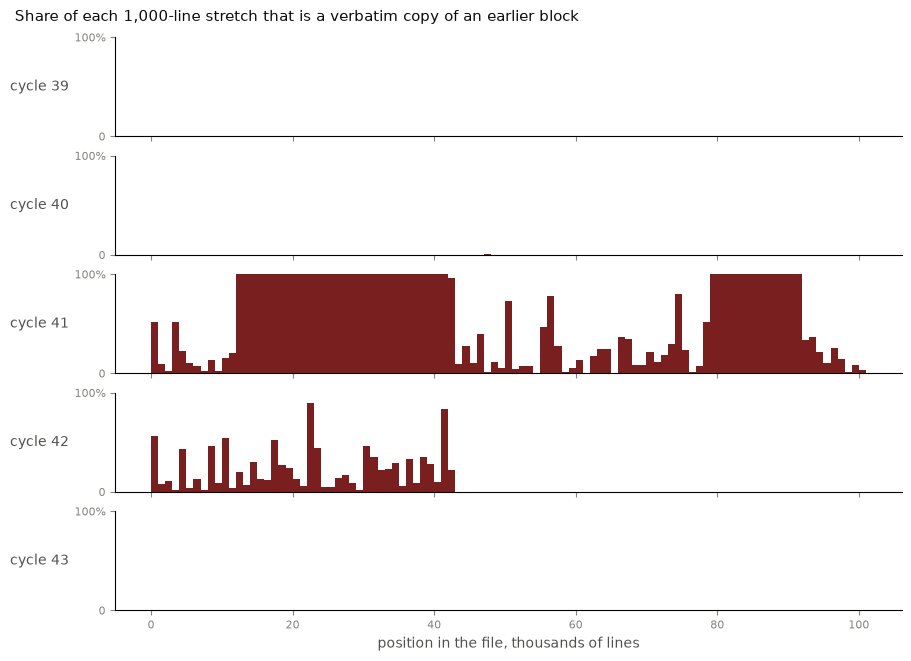

In [15]:
def duplicated_share_by_window(mask, width=1000):
    return [sum(mask[i:i + width]) / len(mask[i:i + width]) for i in range(0, len(mask), width)]


fig, axes = plt.subplots(len(CYCLES), 1, figsize=(9, 6.5), sharex=True, constrained_layout=True)
for ax, c in zip(axes, CYCLES):
    share = duplicated_share_by_window(masks[c])
    ax.fill_between(range(len(share)), share, step="post", color="#7a1f1f", linewidth=0)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 1], ["0", "100%"])
    ax.set_ylabel(f"cycle {c}", rotation=0, ha="right", va="center", color="#52514e")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#86847d", labelsize=8)
plt.close(fig)
axes[-1].set_xlabel("position in the file, thousands of lines", color="#52514e")
fig.suptitle("Share of each 1,000-line stretch that is a verbatim copy of an earlier block",
             x=0.01, ha="left", fontsize=11, color="#0b0b0b")
fig

Two things the files cannot tell us, and the database could:

- **Where the copies come from.** A row multiplied by a join, or one sitting's
  transcript attached to every one of its 176 votes, would both produce exactly
  this pattern. It needs the export code and `parlamonitor.db`, and neither is
  on this machine.
- **Whether the first copy is complete.** Deduplication keeps the first
  occurrence of each block. If the copies overlap partially, a line at a block
  edge can survive twice. That bounds the error at a few lines per block, not
  the 45,479 lines the copies contribute.

What *is* settled: 176 copies of a sitting are not 176 sittings, so every
cycle-41 and cycle-42 figure in the Task 3 and Task 4 reports is inflated.
§4 measures by how much.

## 3. The `Bóna Zoltán jelzésére:` anomaly was the copies

Task 3 flagged `Bóna#Zolta#jelzés` (8,721 occurrences, 93% removed by
collapsing) as the strongest sign of an extraction artifact. Run-aware
deduplication settles it:

In [17]:
for key in ("Bóna Zoltán jelzésére:", "Folyamatos sípolás."):
    before, after = Counter(corpus[41])[key], Counter(deduped[41])[key]
    longest_before = max((n for l, n in runs_of(corpus[41]) if l == key), default=0)
    print(f"{key:26s} as-is {before:6,} (longest run {longest_before})  →  block-dedup {after:5,}")

# The draft's mistake, reproduced: line-level dedup leaves runs inside copies and joins them.
draft = [l for l, dup in zip(corpus[41], line_window_mask(corpus[41])) if not dup]
artefact = max(n for l, n in runs_of(draft) if l == "Bóna Zoltán jelzésére:")
raw_longest = max(n for l, n in runs_of(corpus[41]) if l == "Bóna Zoltán jelzésére:")
print(f"\nline-level dedup would leave a 'Bóna Zoltán jelzésére:' run of {artefact:,} lines; "
      f"the raw file's longest is {raw_longest}")

Bóna Zoltán jelzésére:     as-is  8,721 (longest run 45)  →  block-dedup    81
Folyamatos sípolás.        as-is 15,840 (longest run 11)  →  block-dedup    90

line-level dedup would leave a 'Bóna Zoltán jelzésére:' run of 4,925 lines; the raw file's longest is 45


In the raw file, no run of `Bóna Zoltán jelzésére:` is longer than a few
dozen lines. Its 8,721 occurrences are mostly copies of the blocks around a
voting sequence, which began after members reported that their voting machines
did not work. The same goes for the continuous whistling. Both were real
events, recorded once each and then multiplied by the copying.

## 4. Leaked speech text, and how far the headline numbers move

The extractor's `( … )` matching breaks on nested parentheses. When it does,
it returns the stage direction **plus the speech text that follows it**.

In [18]:
leaked = {c: [l for l in corpus[c] if l.startswith("(")] for c in CYCLES}
leaked_dedup = {c: [l for l in deduped[c] if l.startswith("(")] for c in CYCLES}
pd.DataFrame({
    "lines starting with '('": {c: len(v) for c, v in leaked.items()},
    "after block dedup": {c: len(v) for c, v in leaked_dedup.items()},
    "words in them, after dedup": {c: sum(len(l.split()) for l in v) for c, v in leaked_dedup.items()},
}).rename_axis("cycle")

,lines starting with '(',after block dedup,"words in them, after dedup"
cycle,,,
39,6,6,41
40,8,8,713
41,181,6,847
42,1,1,44
43,0,0,0


In [13]:
for line in sorted(set(leaked_dedup[41]), key=len)[-2:]:
    print("·", line[:260], "…\n")

· (Folyamatos sípolás. - Kunhalmi Ágnes két lapot tart a kezében, amelyeken a felirat: „Külföldre megyek, mert nem túlórázhatok eleget”, „Multik kormánya”.) Most a zárószavazás következik. Felhívom szíves figyelmüket, hogy az Alaptörvény meghatározza az egységes …

· (Jobbik): Tisztelt Elnök Úr! Tisztelt Ház! Valóban, a kormány válaszára nem számíthatunk, hiszen ahogy a szociális védőháló, ugyanúgy elpárolgott a kormány is, képviselői egyszerűen nem találhatók meg a teremben, kivéve a tisztelt levezető elnök személyét, és  …



Leaked text is small once the copies are gone. It is still speech
text inside a stage-direction corpus, though: a chair's announcement of a final
vote, counted as if the note-taker had written it.

**How the headlines move.** Reaction rates are recomputed per 1,000 lines with
the Task 4 classifier (`reactions.events_in`) under three views:

- **as-is**: the file as it stands;
- **collapsed**: `collapse_consecutive`, the Task 3 alternative;
- **block-dedup**: the blocks from §2 removed.

The as-is column must reproduce Task 4's `reaction_summary.csv` exactly. That
is the reconciliation check, and it passes for all five kinds in all five
cycles.

It does **not** reproduce the heckling row of `data/derived/reactions/REPORT.md`.
There the report gives cycle 39 96.0 per 1,000, against 117.3 in its own CSV.
The whistling, laughter and bell rows agree, so the report's heckling row looks
stale against a later classifier change. It is flagged in §8, not corrected
here.

In [19]:
@lru_cache(maxsize=None)
def kinds_in(line):
    return tuple(k for event in events_in(line) for k in event.kinds if k is not Kind.OTHER)


def rates(lines, kinds=("heckling", "whistling", "applause", "laughter", "bell")):
    counts = Counter(k.value for line in lines for k in kinds_in(line))
    return {k: counts[k] / len(lines) * 1000 for k in kinds}


views = {
    "as-is": corpus,
    "collapsed": {c: collapse_consecutive(corpus[c]) for c in CYCLES},
    "block-dedup": deduped,
}
frames = []
for view, data in views.items():
    for c in CYCLES:
        frames.append({"view": view, "cycle": c, "lines": len(data[c]), **rates(data[c])})
moves = pd.DataFrame(frames).set_index(["cycle", "view"]).sort_index().round(1)

# Reconciliation: the as-is view must reproduce Task 4's own machine output,
# data/derived/reactions/reaction_summary.csv (per-kind, summed over audiences).
summary = pd.read_csv(DERIVED / "reactions" / "reaction_summary.csv")
published = summary.groupby(["cycle", "kind"])["per_1000_parentheticals"].sum()
for c in CYCLES:
    for kind in ("heckling", "whistling", "applause", "laughter", "bell"):
        expected = published.get((c, kind), 0.0)
        assert abs(moves.loc[(c, "as-is"), kind] - expected) < 0.05, (c, kind, expected)
moves

lines  heckling  whistling  applause  laughter  bell
cycle view                                                              
39    as-is         59891     117.3        0.2     493.0      43.8  89.2
      block-dedup   59891     117.3        0.2     493.0      43.8  89.2
      collapsed     56139     122.3        0.2     475.8      45.3  90.9
40    as-is         50826     110.9        0.0     429.9      32.4  85.8
      block-dedup   50816     111.0        0.0     429.8      32.4  85.8
      collapsed     48078     113.7        0.0     409.8      33.4  88.2
41    as-is        101446     110.3      208.8     214.4      28.7  43.9
      block-dedup   46169     133.7        3.0     388.8      40.2  82.7
      collapsed     80007     136.2      148.1     246.4      35.4  53.5
42    as-is         43978      94.2        0.0     319.7      33.0  62.9
      block-dedup   33639      95.7        0.1     370.9      34.6  74.3
      collapsed     40996      97.9        0.0     303.0      34.1  65.3
43    as-is          5794     146.4        1.0     421.6     113.7  54.7
      block-dedup    5794     146.4        1.0     421.6     113.7  54.7
      collapsed      5342     152.6        1.1     395.5     114.4  56.3

Cycle 41 changes character. Whistling, the signature of that cycle in the
Task 4 report, almost disappears. The 2018 protest was one sitting, recorded
once and copied 176 times. Applause and the chair's bell rise once the copies
stop diluting them. Cycle 42 shifts the same way, more mildly.

`collapsed`, the Task 3 alternative, moves cycle 41 the wrong way on heckling,
up to 136. It removes adjacent repeats of formulaic lines and leaves the copied
blocks in place.

Named hecklers move more, because the copied blocks are full of the same few
voices:

In [15]:
@lru_cache(maxsize=None)
def interjectors_in(line):
    return tuple(e.speaker for e in events_in(line) if e.kind is Kind.INTERJECTION and e.speaker)


def top_hecklers(lines, n=8):
    return Counter(s for line in lines for s in interjectors_in(line))


rows = []
for c in (41, 42):
    before, after = top_hecklers(corpus[c]), top_hecklers(deduped[c])
    rank_after = {name: r + 1 for r, (name, _) in enumerate(after.most_common())}
    for rank, (name, n) in enumerate(before.most_common(8), start=1):
        rows.append({"cycle": c, "interjector": name, "rank as-is": rank, "as-is": n,
                     "block-dedup": after[name], "rank after": rank_after.get(name),
                     "removed": f"{1 - after[name] / n:.0%}"})
hecklers = pd.DataFrame(rows)
hecklers

,cycle,interjector,rank as-is,as-is,block-dedup,rank after,removed
0,41,Vadai Ágnes,1,2164,852,4,61%
1,41,Bana Tibor,2,1987,62,33,97%
2,41,Arató Gergely,3,1798,777,5,57%
3,41,Kárpát Dániel,4,1503,1150,2,23%
4,41,Varga László,5,1479,59,37,96%
5,41,Rétvári Bence,6,1273,1270,1,0%
6,41,Nacsa Lőrinc,7,976,941,3,4%
7,41,Kunhalmi Ágnes,8,973,160,17,84%
8,42,Rétvári Bence,1,1511,1410,1,7%
9,42,Nacsa Lőrinc,2,1375,1183,2,14%


## 5. Why this matters beyond Task 3 and Task 4

- **`heckler_scores.csv`** and the pooled heckler table rank cycle-41 and
  cycle-42 interjectors partly by how often a duplicated block mentions them.
- **The Task 3 cross-cycle frequency table.** More than half of cycle 41's
  lines in every pooled `ALL` row are copies.
- **Cycle 43**, which drives the dashboard and every MP-level score, has no
  block duplication at all. Nothing published about cycle 43 moves.

## 6. Name repair without an external gazetteer

emMorph has no list of Hungarian MPs, so it lemmatises surnames that are also
words as those words: `Rétvári` → `rétvári`, `Gőgös` → `gőgös`. It also strips
"suffixes" off given names: `Zoltán` → `Zolta` (superessive) and `Novák` →
`Nova` (plural).

The names are already in the corpus, though. The 631 interjector and addressee
names that `reactions.events_in` finds, plus the cycle-43 speaker labels, are
a gazetteer built from the data itself.

**The trap is single-token matching.** `Nagy` is a surname and also the
adjective in `Nagy taps.` ("great applause"). `Szél` is a surname and also
"wind". So the prototype only repairs a token **inside a full name sequence**
the corpus attests, e.g. `Nagy Csaba`, `Szél Bernadett`. The last token may
carry a case suffix (`Kunhalmi Ágnesnek`).

There is one guard. If emtsv's own lemma is capitalised and *longer* than the
corpus name token, emtsv is kept. This covers the name list holding a truncated
form (`Mihál`) where emtsv correctly produced `Mihály`.

In [20]:
cache = {}
with (DERIVED / "parentheticals" / "lemma_cache.jsonl").open(encoding="utf-8") as handle:
    for raw in handle:
        record = json.loads(raw)
        cache[record["line"]] = record["sentences"]
line_weight = Counter(l for c in CYCLES for l in deduped[c])
missing = [l for l in line_weight if l not in cache]
print(f"{len(cache):,} cached lines; {len(missing)} block-dedup lines not in the cache")

names = set()
for c in CYCLES:
    for line in set(corpus[c]):
        for event in events_in(line):
            names.update(n for n in (event.speaker, event.addressee) if n)
names.update(r["speaker"]["label"] for r in speeches if (r.get("speaker") or {}).get("label"))

TITLES = {"dr.", "Dr.", "id.", "ifj.", "özv."}


def name_tokens(name):
    return tuple(t for t in name.split() if t not in TITLES and not (len(t) == 2 and t.endswith(".")))


sequences = {name_tokens(n) for n in names}
sequences = {s for s in sequences if len(s) >= 2}
by_first = defaultdict(list)
for seq in sequences:
    by_first[seq[0]].append(seq)
for candidates in by_first.values():
    candidates.sort(key=lambda seq: (-len(seq), seq))  # longest first; ties broken deterministically
print(f"{len(names):,} names → {len(sequences):,} multi-token name sequences")

64,511 cached lines; 0 block-dedup lines not in the cache
746 names → 744 multi-token name sequences


In [23]:
def match_name(sentence, i):
    # Longest attested name starting at token i, or None. The last token may be inflected.
    for seq in by_first.get(sentence[i][0], ()):
        if i + len(seq) > len(sentence):
            continue
        if all(
            sentence[i + k][0] == t
            or (k == len(seq) - 1 and sentence[i + k][0].startswith(t) and len(sentence[i + k][0]) > len(t))
            for k, t in enumerate(seq)
        ):
            return seq
    return None


def keep_emtsv(lemma, name_token):
    return lemma[:1].isupper() and len(lemma) > len(name_token)


def repair_names(sentence):
    # Return (sentence, [(form, old_lemma, new_lemma), ...]) with name lemmas restored.
    out, changes, i = [list(t) for t in sentence], [], 0
    while i < len(out):
        seq = match_name(out, i)
        if seq is None:
            i += 1
            continue
        for k, token in enumerate(seq):
            form, lemma, _ = out[i + k]
            if lemma != token and not keep_emtsv(lemma, token):
                changes.append((form, lemma, token))
                out[i + k][1] = token
        i += len(seq)
    return out, changes


# Worked examples, checked by hand.
fixed, ch = repair_names([["Gőgös", "gőgös", "[/Adj][Nom]"], ["Zoltán", "Zolta", "[/N][Supe]"], [":", ":", "[Punct]"]])
assert [t[1] for t in fixed] == ["Gőgös", "Zoltán", ":"], fixed
assert repair_names([["Nagy", "nagy", "[/Adj][Nom]"], ["taps", "taps", "[/N][Nom]"]])[1] == []
# The guard: emtsv's capitalised, longer lemma beats a truncated corpus name token.
assert keep_emtsv("Mihály", "Mihál") and not keep_emtsv("Zolta", "Zoltán") and not keep_emtsv("rétvári", "Rétvári")

In [24]:
changed, example_line = Counter(), {}
nagy_taps_before = nagy_taps_after = 0
for line, weight in line_weight.items():
    for sentence in cache.get(line, []):
        repaired, changes = repair_names(sentence)
        for form, old, new in changes:
            changed[(new, old)] += weight
            example_line.setdefault((new, old), line)
        for before, after in zip(sentence, repaired):
            if before[0] == "Nagy" and before[1] == "nagy":
                nagy_taps_before += weight
                nagy_taps_after += weight * (after[1] == "nagy")

print(f"tokens re-lemmatised (block-dedup view): {sum(changed.values()):,} "
      f"across {len({n for n, _ in changed}):,} name tokens")
print(f"capitalised 'Nagy' read as the adjective: {nagy_taps_before:,} before, {nagy_taps_after:,} still the adjective after")
draft = pd.DataFrame(
    [{"form_lemma": new, "emtsv_lemma": old, "tokens": n, "example": example_line[(new, old)][:80], "checked_by_human": False}
     for (new, old), n in changed.most_common()]
)
draft.to_csv(SCRATCH / "name_gazetteer_draft.csv", index=False)
print(f"draft written to {rel(SCRATCH / 'name_gazetteer_draft.csv')}")
draft.head(20)

tokens re-lemmatised (block-dedup view): 29,085 across 145 name tokens
capitalised 'Nagy' read as the adjective: 927 before, 918 still the adjective after
draft written to data/derived/explore/name_gazetteer_draft.csv


,form_lemma,emtsv_lemma,tokens,example,checked_by_human
0,Zoltán,Zolta,4629,Nagy taps. - Balczó Zoltán felállva köszöni meg a tapsot.,False
1,Rétvári,rétvári,3664,Dr. Rétvári Bence: Igen.,False
2,János,jános,2357,"Nagy taps. - Dr. Horváth János korelnök az elnöki emelvényre lép, s kezet fog dr",False
3,Gőgös,gőgös,2161,Gőgös Zoltán: Most kiről van szó?,False
4,Novák,Nova,1186,Taps. - Novák Előd: Éljen a gárda!,False
5,Szilágyi,szilágyi,1136,Taps. - Szilágyi Péter felállva köszöni meg a tapsot.,False
6,Előd,előd,1136,Taps. - Novák Előd: Éljen a gárda!,False
7,Borbély,borbély,1123,Borbély Lénárd nemet int.,False
8,Timea,Time,1032,Szabó Timea jelzésére:,False
9,Babák,baba,899,Babák Mihály: Nem ezt mondtam.,False


In [25]:
# Audit the riskiest token: every context where a capitalised 'Nagy' became the name.
nagy_contexts = Counter()
for line, weight in line_weight.items():
    for sentence in cache.get(line, []):
        repaired, _ = repair_names(sentence)
        for i, (before, after) in enumerate(zip(sentence, repaired)):
            if before[0] == "Nagy" and before[1] == "nagy" and after[1] == "Nagy":
                nagy_contexts[" ".join(t[0] for t in sentence[i:i + 3])] += weight
assert not any(ctx.split()[1:2] == ["taps."] or ctx.startswith("Nagy taps") for ctx in nagy_contexts)
pd.DataFrame(nagy_contexts.most_common(8), columns=["context", "tokens"])

,context,tokens
0,Nagy Ervin :,7
1,Nagy Ervin közbeszól,1
2,Nagy Ervin Takács,1


In [26]:
# How the Task 3 n-gram display forms would read after the repair.
ngrams = pd.read_csv(DERIVED / "parentheticals" / "significant_ngrams.csv")
fix = defaultdict(set)
for new, old in changed:
    fix[old].add(new)


def redisplay(token):
    # Re-spell an n-gram only where the repaired parts form an attested name,
    # so 'nagy#taps' stays the adjective while 'nagy#Csaba' becomes 'Nagy#Csaba'.
    parts = token.split("#")
    options = [sorted(fix.get(p, set())) + [p] for p in parts]
    for start in range(len(parts)):
        for end in range(start + 2, len(parts) + 1):
            for seq in sorted(sequences):
                if len(seq) == end - start and all(seq[k] in options[start + k] for k in range(len(seq))):
                    parts[start:end] = list(seq)
    return "#".join(parts)


assert redisplay("nagy#taps") == "nagy#taps"
affected = ngrams.assign(**{"after repair": ngrams["token"].map(redisplay)})
affected = affected[affected["token"] != affected["after repair"]]
print(f"{len(affected):,} of {len(ngrams):,} significant n-grams change display form")
affected[["token", "after repair", "raw"]].sort_values("raw", ascending=False).head(15)

478 of 3,524 significant n-grams change display form


,token,after repair,raw
5,Bóna#Zolta#jelzés,Bóna#Zoltán#jelzés,8721
23,dr.#rétvári#Bence,dr.#Rétvári#Bence,2129
39,Bangóné#borbély#Ildikó,Bangóné#Borbély#Ildikó,1282
43,gőgös#Zolta,Gőgös#Zoltán,1112
45,Szabó#Time,Szabó#Timea,1083
49,szilágyi#György,Szilágyi#György,983
56,rétvári#Bence,Rétvári#Bence,876
66,dr.#szél#Bernadett,dr.#Szél#Bernadett,722
69,Nova#előd,Novák#Előd,716
72,dr.#latorcai#jános,dr.#Latorcai#János,676


The repair is a **lemma** fix only. It changes no token boundaries, so every
count in Task 3 stays the same, with one exception: a name whose lemma
currently collides with a common word. Today those counts are merged with the
common word. `rétvári`, for instance, would no longer be counted together with
the adjective "of Rétvár".

The draft table is gitignored scratch. The promotion path is a hand-checked
copy in `data/labels/`, the same pattern as `task2_topic_names.json`.

## 7. `Mi Hazánk` as one name

emtsv reads `Mi Hazánk` as the pronoun `mi` plus `haza[Poss.1Pl]` ("our
homeland"). The prototype merges a capitalised `Mi` followed by a capitalised
form starting with `Hazánk` into a single token with lemma `Mi Hazánk`. A
lowercase *mi hazánk* is the ordinary phrase and must stay untouched.

In [27]:
def merge_mi_hazank(sentence):
    out, i, n = [], 0, 0
    while i < len(sentence):
        form, lemma, tag = sentence[i]
        if form == "Mi" and i + 1 < len(sentence) and sentence[i + 1][0].startswith("Hazánk"):
            nxt = sentence[i + 1][0]
            suffix = nxt[len("Hazánk"):]  # "-frakció", "kat", "nak" …
            lemma_out = "Mi Hazánk" + (suffix if suffix.startswith("-") else "")
            out.append([f"Mi {nxt}", lemma_out, "[/N][Nom]"])
            i, n = i + 2, n + 1
        else:
            out.append(sentence[i])
            i += 1
    return out, n


assert merge_mi_hazank([["Mi", "mi", "[/N|Pro][1Pl][Nom]"], ["Hazánk", "haza", "[/N][Poss.1Pl][Nom]"]])[0][0][1] == "Mi Hazánk"
assert merge_mi_hazank([["mi", "mi", "[/N|Pro]"], ["hazánk", "haza", "[/N][Poss.1Pl]"]])[1] == 0
assert merge_mi_hazank([["Mi", "mi", "[/N|Pro]"], ["Hazánk-frakció", "Hazánk-frakció", "[/N]"]])[0][0][1] == "Mi Hazánk-frakció"

merged, lowercase_pairs = Counter(), 0
for line, weight in line_weight.items():
    for sentence in cache.get(line, []):
        out, n = merge_mi_hazank(sentence)
        if n:
            for token in out:
                if token[1].startswith("Mi Hazánk"):
                    merged[token[1]] += weight
        lowercase_pairs += weight * sum(
            a[0] == "mi" and b[0].startswith("hazánk") for a, b in zip(sentence, sentence[1:])
        )
print(f"merged: {dict(merged)}")
print(f"lowercase 'mi hazánk…' pairs left alone: {lowercase_pairs}")
ngrams.loc[ngrams["token"].str.contains("mi#haza"), ["token", "raw", "raw_c42", "raw_c43"]]

merged: {'Mi Hazánk': 914, 'Mi Hazánk-frakció': 6}
lowercase 'mi hazánk…' pairs left alone: 1


,token,raw,raw_c42,raw_c43
63,taps#a#mi#haza,771,627,144
468,mi#haza,149,105,41
1460,szórványos#taps#a#mi#haza,19,18,1


## 8. Findings, what to promote, and decisions for you

**Findings**

1. **The exporter does not invent adjacent repeats.** In cycle 43, 92% of
   consecutive repeats are separate stage directions in the transcript. The
   rest fall mostly in the chair's turns, which can't be checked.
2. **Cycles 41 and 42 contain verbatim block copies.** They make up 54.5% and
   23.5% of those files. The 12 December 2018 protest block is written 176
   times. This is not the duplication Task 3 measured, and `raw_collapsed` does
   not remove it.
3. **The Task 3 anomalies were the copies.** Once the blocks are removed,
   `Bóna Zoltán jelzésére:` (8,721 → 81) and `Folyamatos sípolás.`
   (15,840 → 90) shrink to under a hundred each. Cycle 41's adjacent-repeat rate returns to the range of
   the other cycles. Line-level deduplication gets this wrong: it manufactures
   long runs out of the leftovers (§3).
4. **Leaked speech text** from nested parentheses is small once the copies are
   removed, but nonzero (§4).
5. **Corpus-internal name repair** fixes surname and given-name lemmas without
   touching `Nagy taps`. It changes the display form of 478 of the 3,524
   Task 3 n-grams. **`Mi Hazánk`** merges cleanly: 920 tokens, and the one
   lowercase *mi hazánk* is left alone.
6. **Task 4's `REPORT.md` heckling row disagrees with its own CSV** (§4).

**What to promote into `src/parlamonitor/`**

- `block_copy_mask` (run-aware) → `parentheticals.py`, with doctests and
  Hypothesis properties:
  - never flags a file with no repeated window;
  - leaves the first occurrence of every block;
  - is idempotent on its own output.
- `repair_names` and `merge_mi_hazank` → `propernouns.py`. The name list is
  built from the corpus, and the reviewed table lives in `data/labels/`.
- A **block-dedup view** next to `raw` and `raw_collapsed` in every Task 3 CSV,
  and in the Task 4 summary.

**Decisions for you**

- **Which view is the default for cycles 41–42.** I'd recommend block-dedup for
  any cross-cycle comparison, and keeping as-is in the files for provenance.
- **Task 4 `REPORT.md` heckling row.** It disagrees with `reaction_summary.csv`
  (§4). Regenerate the report from the CSV.
- **Leaked lines.** Trim at the closing `)`, or drop the line.
- **Re-exporting with sitting IDs.** This is the only way to find *why* the
  database holds copies (§2). It needs the application repo.
- **Window.** `block_window_runs=10`. It is the shortest window that flags
  nearly nothing in cycles 39, 40 and 43 (0–10 lines), and longer windows
  change cycles 41–42 by less than 1% (§2 sensitivity table).